In [1]:
import pandas as pd

# Notebook dosyasının bulunduğu dizine göre bağıl yol (relative path) tanımlaması
file_path = "../data/Temel İşgücü Göstergeleri (TR,DF_ISGUCU_CEYREK_TEMEL_ISGUCU_C,1.0).csv"

# Veri setinin ayırıcı parametresi ile yüklenmesi
df = pd.read_csv(file_path, sep=';')

# Veri setinin boyutları ve yapısal özeti
print(f"Satır ve Sütun Sayısı: {df.shape}")
print("-" * 50)
print(df.info())

Satır ve Sütun Sayısı: (2064, 30)
--------------------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 2064 entries, 0 to 2063
Data columns (total 30 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   REF_AREA                           2064 non-null   str    
 1   Coğrafi Kapsam (TR)                2064 non-null   str    
 2   INDICATOR                          2064 non-null   str    
 3   İstatistiksel Gösterge (ISGI_TIG)  2064 non-null   str    
 4   TEMEL_YAS                          2064 non-null   str    
 5   Temel Yaş (Y_GE15)                 2064 non-null   str    
 6   SEASONAL_ADJUST                    2064 non-null   str    
 7   Mevsimsel Düzeltme (S)             2064 non-null   str    
 8   ISGUCU_GOSTERGE                    2064 non-null   int64  
 9   İşgücü Göstergeleri (1)            2064 non-null   str    
 10  FREQ                               2064 non-nu

In [5]:
import pandas as pd
import scipy.stats as stats

# 1. Verinin yüklenmesi ve tip dönüşümleri
dosya_yolu_orijinal = "../data/Temel İşgücü Göstergeleri (TR,DF_ISGUCU_CEYREK_TEMEL_ISGUCU_C,1.0).csv"
df = pd.read_csv(dosya_yolu_orijinal, sep=';')
df['Gözlem Değeri Num'] = df['Gözlem Değeri'].astype(str).str.replace(',', '.').astype(float)

# 2. İşgücüne Katılma Oranı (İKO) verisinin filtrelenmesi
df_iko = df[df['İşgücü Göstergeleri (1)'] == 'İşgücüne Katılma Oranı (%)']

# 3. Cinsiyete göre serilerin ayrıştırılması
kadin_iko = df_iko[df_iko['Cinsiyet (_T)'] == 'Kadın']['Gözlem Değeri Num'].dropna()
erkek_iko = df_iko[df_iko['Cinsiyet (_T)'] == 'Erkek']['Gözlem Değeri Num'].dropna()

# 4. Normallik varsayımının sınanması (Shapiro-Wilk)
stat_k, p_k = stats.shapiro(kadin_iko)
stat_e, p_e = stats.shapiro(erkek_iko)

print(f"Normallik p-değerleri -> Kadın: {p_k:.4e}, Erkek: {p_e:.4e}")
# Çıktı, dağılımın normal olmadığını ve parametrik olmayan bir testin zorunlu olduğunu göstermektedir.

# 5. Mann-Whitney U Testinin uygulanması
u_stat, p_degeri = stats.mannwhitneyu(kadin_iko, erkek_iko, alternative='two-sided')

# 6. Bulguların raporlanması
print("-" * 50)
print(f"Kadın İKO Ortalaması: %{kadin_iko.mean():.2f}")
print(f"Erkek İKO Ortalaması: %{erkek_iko.mean():.2f}")
print(f"Mann-Whitney U İstatistiği: {u_stat:.2f}")
print(f"P-değeri: {p_degeri:.2e}")

if p_degeri < 0.05:
    print("Sonuç: İşgücüne katılımdaki yapısal uçurum istatistiksel olarak anlamlıdır (p < 0.05).")

Normallik p-değerleri -> Kadın: 1.2706e-05, Erkek: 6.0197e-06
--------------------------------------------------
Kadın İKO Ortalaması: %29.59
Erkek İKO Ortalaması: %69.80
Mann-Whitney U İstatistiği: 0.00
P-değeri: 9.96e-30
Sonuç: İşgücüne katılımdaki yapısal uçurum istatistiksel olarak anlamlıdır (p < 0.05).


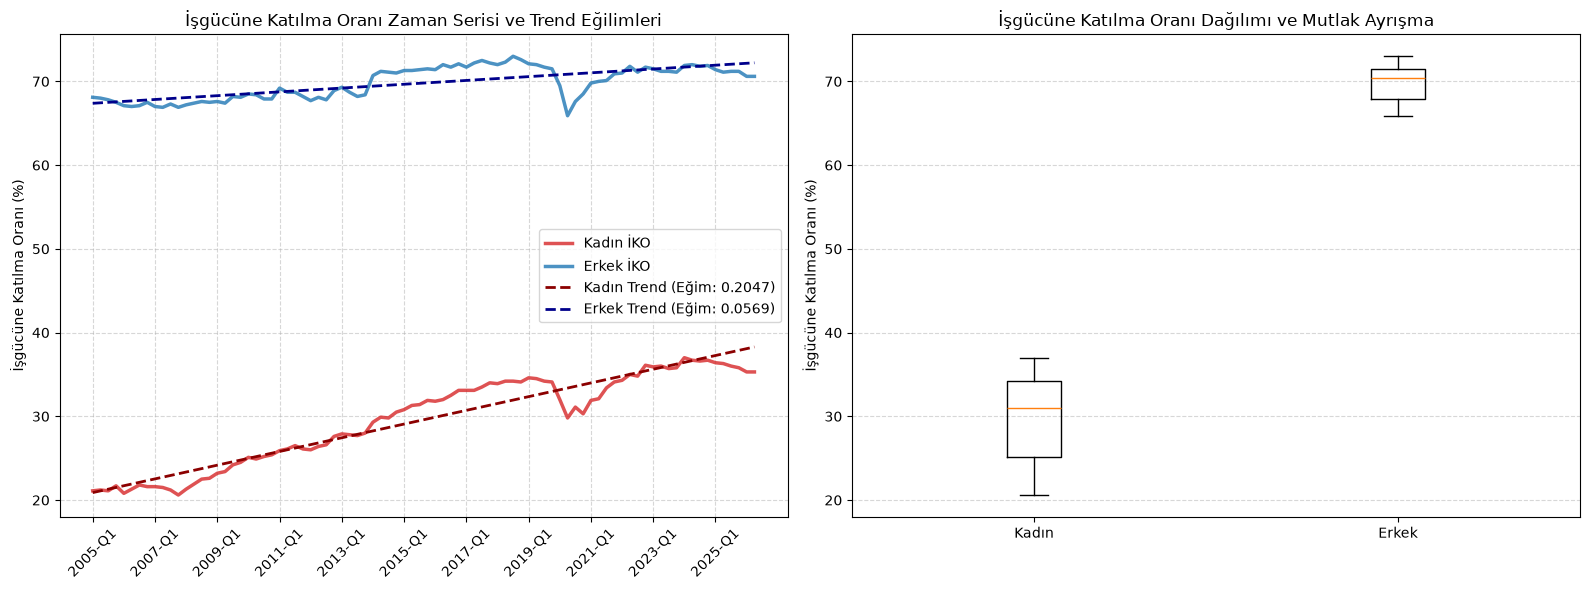

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Veriyi yükleme ve tip dönüşümü
dosya_yolu = "../data/Temel İşgücü Göstergeleri (TR,DF_ISGUCU_CEYREK_TEMEL_ISGUCU_C,1.0).csv"
df = pd.read_csv(dosya_yolu, sep=';')
df['Gözlem Değeri Num'] = df['Gözlem Değeri'].astype(str).str.replace(',', '.').astype(float)

# 2. Tarih formatını standartlaştırıp kronolojik sıralama
df['Tarih'] = pd.to_datetime(df['Zaman (TIME_PERIOD)'].str.replace('-Q1', '-01-01').str.replace('-Q2', '-04-01').str.replace('-Q3', '-07-01').str.replace('-Q4', '-10-01'))
df_iko = df[df['İşgücü Göstergeleri (1)'] == 'İşgücüne Katılma Oranı (%)'].sort_values('Tarih')

# 3. Cinsiyete göre serileri ayırma ve indeks sıfırlama
kadin_iko = df_iko[df_iko['Cinsiyet (_T)'] == 'Kadın'].reset_index(drop=True)
erkek_iko = df_iko[df_iko['Cinsiyet (_T)'] == 'Erkek'].reset_index(drop=True)

# 4. Zaman Serisi Regresyonu (Trend Eğimi) - np.polyfit ile Pylance uyumlu çözüm
x_ekseni = np.arange(len(kadin_iko))

egim_k, kesisim_k = np.polyfit(x_ekseni, kadin_iko['Gözlem Değeri Num'], 1)
egim_e, kesisim_e = np.polyfit(x_ekseni, erkek_iko['Gözlem Değeri Num'], 1)

# 5. Görselleştirme Mimarisi (1x2 Matris)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# --- Grafik 1: Zaman Serisi Eğilimi ve Trend (Sol Panel) ---
ax1.plot(kadin_iko['Zaman (TIME_PERIOD)'], kadin_iko['Gözlem Değeri Num'], label='Kadın İKO', color='#d62728', linewidth=2.5, alpha=0.8)
ax1.plot(erkek_iko['Zaman (TIME_PERIOD)'], erkek_iko['Gözlem Değeri Num'], label='Erkek İKO', color='#1f77b4', linewidth=2.5, alpha=0.8)

# Regresyon (Trend) Doğruları
ax1.plot(kadin_iko['Zaman (TIME_PERIOD)'], kesisim_k + egim_k * x_ekseni, color='darkred', linestyle='--', linewidth=2, label=f'Kadın Trend (Eğim: {egim_k:.4f})')
ax1.plot(erkek_iko['Zaman (TIME_PERIOD)'], kesisim_e + egim_e * x_ekseni, color='darkblue', linestyle='--', linewidth=2, label=f'Erkek Trend (Eğim: {egim_e:.4f})')

ax1.set_title('İşgücüne Katılma Oranı Zaman Serisi ve Trend Eğilimleri')
ax1.set_ylabel('İşgücüne Katılma Oranı (%)')
ax1.set_xticks(ax1.get_xticks()[::8]) # Etiket yığılmasını önlemek için 2 yıllık adımlar
ax1.tick_params(axis='x', rotation=45)
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.5)

# --- Grafik 2: Kutu Grafiği (Sağ Panel) ---
ax2.boxplot([kadin_iko['Gözlem Değeri Num'].dropna(), erkek_iko['Gözlem Değeri Num'].dropna()], tick_labels=['Kadın', 'Erkek'])
ax2.set_title('İşgücüne Katılma Oranı Dağılımı ve Mutlak Ayrışma')
ax2.set_ylabel('İşgücüne Katılma Oranı (%)')
ax2.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### İşgücüne Katılma Oranı (İKO) Analiz Bulguları

**1. İstatistiksel Test Çıktıları (Sayısal Kanıtlar)**
*   **Temel Asimetri:** Kadınların işgücüne katılım ortalaması %29.59 seviyesinde kalırken, erkeklerde bu oran %69.80'dir.
*   **Test Seçimi:** Shapiro-Wilk normallik testi sonuçları (Kadın: 1.27e-05, Erkek: 6.01e-06) 0.05'ten küçük olduğu için verinin normal dağılmadığı matematiksel olarak kanıtlanmış ve Mann-Whitney U testine geçilmiştir.
*   **Mutlak Ayrışma (U=0.00):** U istatistiğinin tam sıfır olması kritik bir bulgudur. Bu değer, 86 çeyreklik verinin hiçbir noktasında iki grubun birbiriyle kesişmediğini gösterir; kadınların ulaştığı maksimum oran bile erkeklerin minimum oranının altındadır.
*   **İstatistiksel Anlamlılık:** P-değerinin sıfıra asimptotik olarak yakın (9.96e-30) çıkması, cinsiyetler arası bu yapısal uçurumun tesadüfi olmadığını ve %99.9 güven düzeyinde anlamlı olduğunu ispatlar.

**2. Görsel Bulgular ve Trend Doğrulaması (Grafikler)**
*   **Dağılım Doğrulaması:** Sağ paneldeki kutu grafiği, istatistiksel testteki "sıfır örtüşme (U=0.00)" sonucunu görselleştirerek iki veri setinin dağılımları arasındaki devasa boşluğu net bir biçimde ortaya koymaktadır.
*   **Zaman İçi İvme:** Soldaki zaman serisi trendine göre, kadınların işgücüne katılımı çeyreklik bazda nispeten hızlı bir ivmeyle (0.2047 eğim) artarken, erkeklerin eğilimi (0.0569 eğim) çok daha durağan ve yatay kalmıştır.
*   **Yakınsama (Convergence) Durumu:** Trend doğrularındaki bu eğim farkı, aradaki devasa makasın zamanla kapanma eğilimi gösterdiğini doğrulamaktadır[cite: 6]. Buna rağmen, iki doğru arasındaki mutlak dikey mesafe, yapısal eşitsizliğin varlığını net bir şekilde sürdürdüğünü kanıtlar.

In [13]:
import pandas as pd
import scipy.stats as stats

# 1. Veriyi yükleme ve tip dönüşümü
dosya_yolu = "../data/Temel İşgücü Göstergeleri (TR,DF_ISGUCU_CEYREK_TEMEL_ISGUCU_C,1.0).csv"
df = pd.read_csv(dosya_yolu, sep=';')
df['Gözlem Değeri Num'] = df['Gözlem Değeri'].astype(str).str.replace(',', '.').astype(float)

# 2. İşsizlik Oranı filtresi
df_issizlik = df[df['İşgücü Göstergeleri (1)'] == 'İşsizlik Oranı (%)']

# 3. Cinsiyete göre serileri ayırma
kadin_issizlik = df_issizlik[df_issizlik['Cinsiyet (_T)'] == 'Kadın']['Gözlem Değeri Num'].dropna()
erkek_issizlik = df_issizlik[df_issizlik['Cinsiyet (_T)'] == 'Erkek']['Gözlem Değeri Num'].dropna()

# 4. Normallik kontrolü (Shapiro-Wilk)
stat_k, p_k = stats.shapiro(kadin_issizlik)
stat_e, p_e = stats.shapiro(erkek_issizlik)

print(f"Normallik p-değerleri -> Kadın: {p_k:.4e}, Erkek: {p_e:.4e}")
# Erkek veri setinin dağılımı normal değil (p < 0.05), Mann-Whitney U testi uygulanmalıdır.

# 5. Mann-Whitney U Testi
u_stat, p_degeri = stats.mannwhitneyu(kadin_issizlik, erkek_issizlik, alternative='two-sided')

# 6. Bulguları yazdırma
print("-" * 50)
print(f"Kadın İşsizlik Ortalaması: %{kadin_issizlik.mean():.2f}")
print(f"Erkek İşsizlik Ortalaması: %{erkek_issizlik.mean():.2f}")
print(f"Mann-Whitney U İstatistiği: {u_stat:.2f}")
print(f"P-değeri: {p_degeri:.2e}")

if p_degeri < 0.05:
    print("Sonuç: Cinsiyetler arası işsizlik farkı istatistiksel olarak anlamlıdır (p < 0.05).")

Normallik p-değerleri -> Kadın: 1.4940e-01, Erkek: 4.8724e-04
--------------------------------------------------
Kadın İşsizlik Ortalaması: %12.04
Erkek İşsizlik Ortalaması: %9.35
Mann-Whitney U İstatistiği: 6175.00
P-değeri: 3.31e-14
Sonuç: Cinsiyetler arası işsizlik farkı istatistiksel olarak anlamlıdır (p < 0.05).


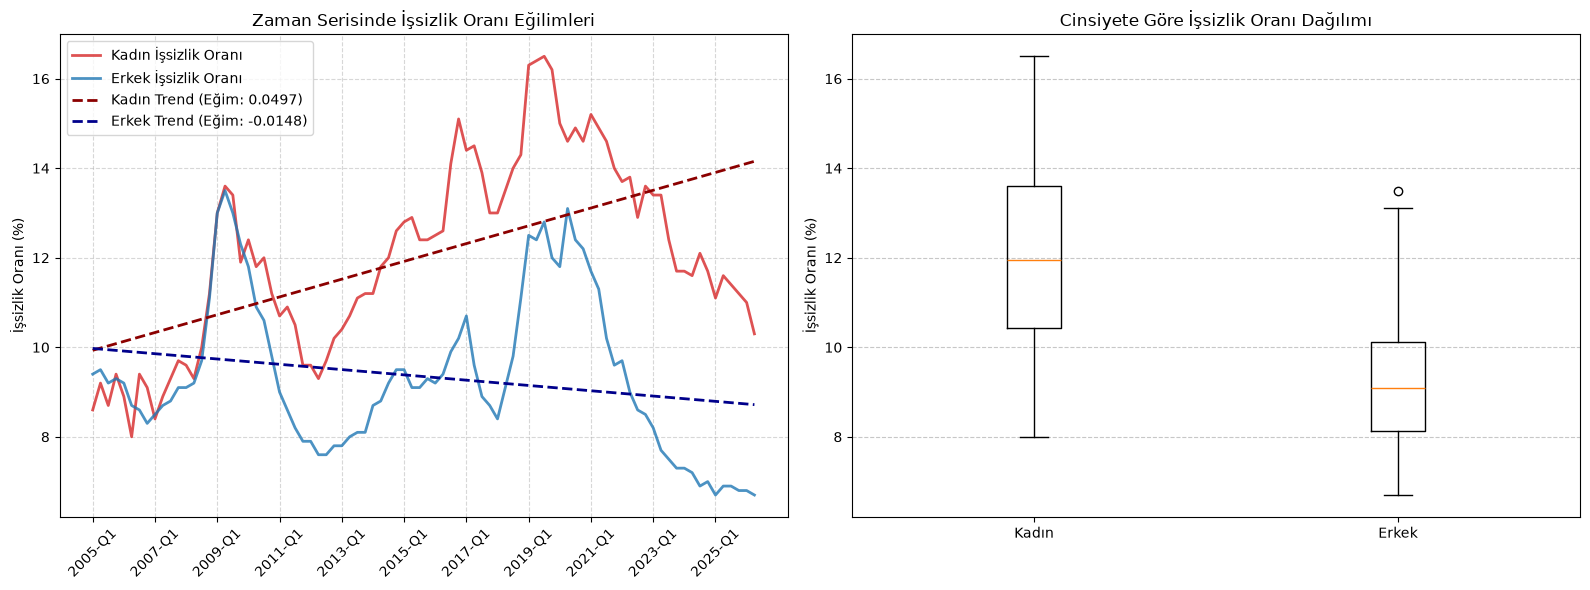

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Veriyi yükleme
dosya_yolu = "../data/Temel İşgücü Göstergeleri (TR,DF_ISGUCU_CEYREK_TEMEL_ISGUCU_C,1.0).csv"
df = pd.read_csv(dosya_yolu, sep=';')
df['Gözlem Değeri Num'] = df['Gözlem Değeri'].astype(str).str.replace(',', '.').astype(float)

# 2. Tarihsel sıralama için veri ön işleme
df['Tarih'] = pd.to_datetime(df['Zaman (TIME_PERIOD)'].str.replace('-Q1', '-01-01').str.replace('-Q2', '-04-01').str.replace('-Q3', '-07-01').str.replace('-Q4', '-10-01'))

# 3. İşsizlik oranını filtreleme ve kronolojik sıralama
df_issizlik = df[df['İşgücü Göstergeleri (1)'] == 'İşsizlik Oranı (%)'].sort_values('Tarih')

kadin_zaman = df_issizlik[df_issizlik['Cinsiyet (_T)'] == 'Kadın'].reset_index(drop=True)
erkek_zaman = df_issizlik[df_issizlik['Cinsiyet (_T)'] == 'Erkek'].reset_index(drop=True)

# 4. Zaman Serisi Regresyonu (SciPy yerine NumPy Polyfit ile Pylance tip hatası çözümü)
x_ekseni = np.arange(len(kadin_zaman))

# np.polyfit 1. derece (doğrusal) uyumda doğrudan [eğim, kesişim] döndürür ve tipleri float64'tür.
egim_k, kesisim_k = np.polyfit(x_ekseni, kadin_zaman['Gözlem Değeri Num'], 1)
egim_e, kesisim_e = np.polyfit(x_ekseni, erkek_zaman['Gözlem Değeri Num'], 1)

# 5. Görselleştirme Mimarisi (1 Satır, 2 Sütun)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# --- Grafik 1: Zaman Serisi Eğilimi (Sol Panel) ---
ax1.plot(kadin_zaman['Zaman (TIME_PERIOD)'], kadin_zaman['Gözlem Değeri Num'], label='Kadın İşsizlik Oranı', color='#d62728', linewidth=2, alpha=0.8)
ax1.plot(erkek_zaman['Zaman (TIME_PERIOD)'], erkek_zaman['Gözlem Değeri Num'], label='Erkek İşsizlik Oranı', color='#1f77b4', linewidth=2, alpha=0.8)

# Regresyon (Trend) Doğruları
ax1.plot(kadin_zaman['Zaman (TIME_PERIOD)'], kesisim_k + egim_k * x_ekseni, color='darkred', linestyle='--', linewidth=2, label=f'Kadın Trend (Eğim: {egim_k:.4f})')
ax1.plot(erkek_zaman['Zaman (TIME_PERIOD)'], kesisim_e + egim_e * x_ekseni, color='darkblue', linestyle='--', linewidth=2, label=f'Erkek Trend (Eğim: {egim_e:.4f})')

ax1.set_title('Zaman Serisinde İşsizlik Oranı Eğilimleri')
ax1.set_ylabel('İşsizlik Oranı (%)')
ax1.set_xticks(ax1.get_xticks()[::8])
ax1.tick_params(axis='x', rotation=45)
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.5)

# --- Grafik 2: Kutu Grafiği (Sağ Panel) ---
ax2.boxplot([kadin_zaman['Gözlem Değeri Num'].dropna(), erkek_zaman['Gözlem Değeri Num'].dropna()], tick_labels=['Kadın', 'Erkek'])
ax2.set_title('Cinsiyete Göre İşsizlik Oranı Dağılımı')
ax2.set_ylabel('İşsizlik Oranı (%)')
ax2.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

### İşsizlik Oranı Analiz Bulguları

**1. İstatistiksel Test Çıktıları (Sayısal Kanıtlar)**
*   **Ortalama Farkı:** Kadınların işsizlik oranı ortalaması %12.04 iken, erkeklerde bu oran %9.35 seviyesindedir.
*   **Test Seçimi:** Shapiro-Wilk normallik testi sonuçlarına göre kadın veri seti normal dağılıma uysa da (p=0.149), erkek veri seti normal dağılım varsayımını ihlal etmiştir (p=0.0004). Bu nedenle, istatistiksel geçerlilik için parametrik olmayan Mann-Whitney U testinin uygulanması doğru ve zorunludur.
*   **İstatistiksel Anlamlılık:** Test sonucunda elde edilen p-değerinin (3.31e-14) sıfıra son derece yakın çıkması, kadın ve erkek işsizlik oranları arasındaki farkın rastlantısal olmadığını ve %99.9 güven düzeyinde istatistiksel olarak anlamlı olduğunu kanıtlar.

**2. Görsel Bulgular ve Trend Doğrulaması (Grafikler)**
*   **Dağılım Farkı:** Sağ paneldeki kutu grafiğinde, kadın işsizlik verisinin çeyreklik aralıklarının ve medyan çizgisinin, erkeklerin dağılımına kıyasla belirgin şekilde daha yukarıda konumlandığı görülmektedir.
*   **Zıt Yönlü İvmeler (Divergence):** Soldaki zaman serisi grafiğinde trend eğimleri incelendiğinde; kadın işsizliğinin zaman içinde yukarı yönlü pozitif bir ivmeyle (0.0497 eğim) arttığı, erkek işsizliğinin ise aşağı yönlü negatif bir ivmeyle (-0.0148 eğim) düştüğü saptanmıştır.
*   **Makasın Açılması:** Trend doğrularındaki bu zıt yönlü hareket, işsizlik oranlarındaki cinsiyet ayrışmasının (makasın) zamanla kapanmadığını, aksine yapısal olarak giderek daha da genişlediğini görsel olarak doğrulamaktadır.

### İşgücü Piyasasında Çift Asimetri

**1. Piyasaya Giriş Bariyeri**
İşgücüne Katılma Oranı (İKO) verilerindeki mutlak ayrışma (U=0.00), cinsiyet eşitsizliğinin temelinin "iş bulamamak" değil, "piyasaya hiç dahil olamamak" olduğunu kanıtlar. Kadınların yaklaşık %70'i çalışma çağında olmalarına rağmen ekonomik üretim sahnesinin tamamen dışındadır. 

**2. İstihdam Edilebilirlik Bariyeri**
Birinci bariyeri aşarak işgücüne dahil olmayı başaran azınlık kadın grubu, iş arama sürecinde de yapısal bir dezavantajla karşılaşmaktadır. Kadın işsizlik oranının (%12.04), erkek işsizlik oranından (%9.35) istatistiksel olarak anlamlı derecede yüksek olması, eşitsizliğin piyasa içinde de katmanlanarak devam ettiğini doğrular.

**3. Makroekonomik Uyumsuzluk**
Her iki göstergenin zaman serisi eğilimleri birleştirildiğinde, piyasadaki yapısal tıkanıklık matematiksel olarak netleşmektedir. Kadınların işgücüne katılımı zamanla ivmeli bir artış (0.2047 eğim) gösterse de, kadın işsizlik oranının da eş zamanlı olarak yükseliş trendinde (0.0497 eğim) olması, ekonominin piyasaya yeni giren bu kadın işgücünü istihdama dönüştüremediğini (absorbe edemediğini) ispatlar. Erkek işsizliği düşüş eğilimindeyken (-0.0148 eğim) kadın işsizliğinin artması, Türkiye işgücü piyasasının net istihdam yaratma kapasitesinin cinsiyete karşı asimetrik çalıştığını kesinleştirir.